# Chapitre 9 - Cours 2 : Optimiser le modèle et contourner le goulot autorégressif

Le cours 1 a montré que le decode est limité par la lecture des poids, un token à la fois.
Deux familles de remèdes agissent **sur le modèle** lui-même : le rendre plus petit
(compression) et produire plusieurs tokens par lecture des poids (décodage spéculatif et
ses cousins). Ce notebook couvre, dans la section *Inference Optimization* du livre :

- l'introduction (*model, hardware, service*) et *Model Optimization* ;
- *Model compression* : quantification, distillation, élagage (*pruning*) ;
- *Overcoming the autoregressive decoding bottleneck* : *Speculative decoding*,
  *Inference with reference*, *Parallel decoding*.

**Plan.** 1. Trois niveaux d'optimisation ; 2. Quantification : poids seuls ou poids et
activations ; 3. Quantification mesurée : mémoire, vitesse, perplexité ; 4. Distillation ;
5. Élagage ; 6. Le goulot autorégressif ; 7. Décodage spéculatif ; 8. Inférence avec
référence ; 9. Décodage parallèle ; Synthèse.

In [1]:
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)


def release(*objs):
    """Libère des modèles chargés hors du cache de llm.load."""
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()

## 1. Trois niveaux d'optimisation (section *Inference Optimization*)

Le livre file la métaphore du tir à l'arc : optimiser le **modèle**, c'est fabriquer de
meilleures flèches ; optimiser le **matériel**, entraîner un archer plus fort ; optimiser le
**service**, régler tout le dispositif (arc, conditions de tir, ordre de passage). En
production on combine les trois. Les techniques au niveau du modèle peuvent **changer son
comportement** : la figure 9-8 du livre montre le même Llama obtenir des scores différents
selon le fournisseur qui le sert. Les techniques de service, elles, ne doivent pas changer
les sorties.

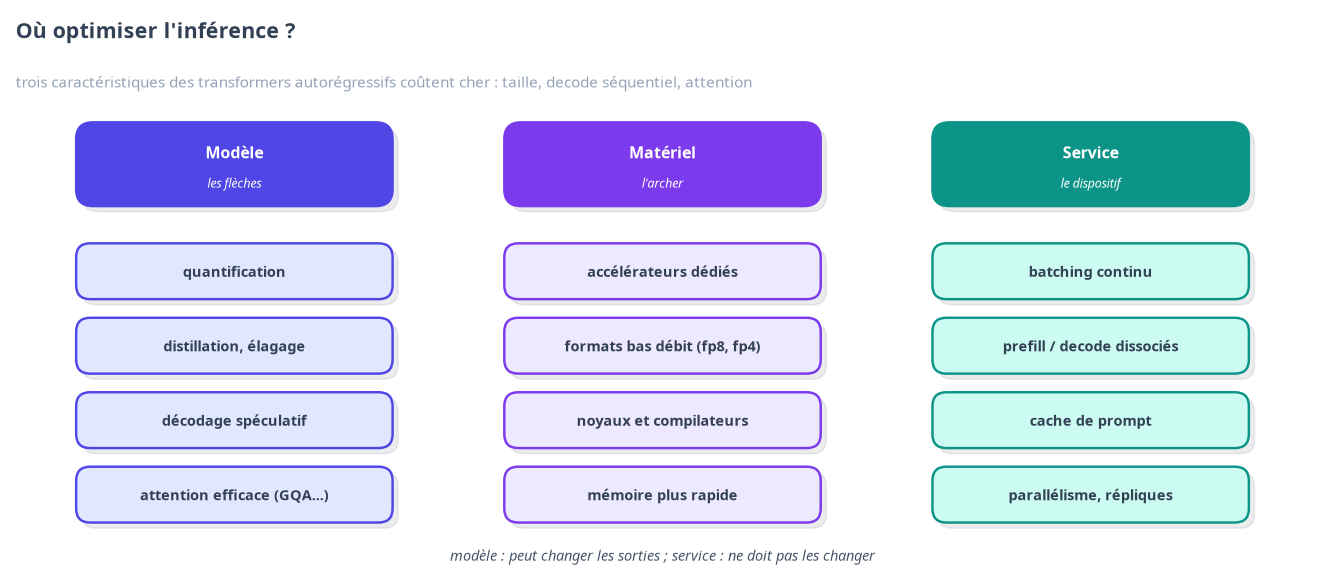

In [2]:
d = Diagram(14, 5.0, title="Où optimiser l'inférence ?",
            subtitle="trois caractéristiques des transformers autorégressifs coûtent cher : taille, decode séquentiel, attention")
cols = [("Modèle", "les flèches", INDIGO, ["quantification", "distillation, élagage", "décodage spéculatif",
                                           "attention efficace (GQA...)"]),
        ("Matériel", "l'archer", VIOLET, ["accélérateurs dédiés", "formats bas débit (fp8, fp4)",
                                         "noyaux et compilateurs", "mémoire plus rapide"]),
        ("Service", "le dispositif", TEAL, ["batching continu", "prefill / decode dissociés",
                                           "cache de prompt", "parallélisme, répliques"])]
for i, (t, sub, c, items) in enumerate(cols):
    x = 2.4 + i * 4.6
    d.box(f"h{i}", x, 4.3, t, sub=sub, color=c, filled=True, w=3.4, h=0.9)
    for j, it in enumerate(items):
        d.box(f"i{i}{j}", x, 3.15 - j * 0.8, it, color=c, w=3.4, h=0.6, fontsize=9.5)
d.note(7.0, 0.1, "modèle : peut changer les sorties ; service : ne doit pas les changer", fontsize=9.5)
d.show()

> **À retenir.** Taille du modèle, decode autorégressif et attention sont les trois sources
> du coût. Les optimisations « modèle » sont puissantes mais doivent être **évaluées**
> (chapitres 3 et 4) : elles peuvent dégrader la qualité.

## 2. Quantification : poids seuls ou poids et activations (section *Model compression*)

Le chapitre 7 a présenté la quantification ; ici, le point de vue est la **vitesse**. En
decode, chaque token impose de lire tous les poids : passer de 16 à 8 bits divise par deux
les octets lus, donc (idéalement) le temps d'un pas.

**Quantification symétrique « absmax ».** Pour $b$ bits, on choisit une échelle
$s = \max |w| / (2^{b-1} - 1)$ et on stocke l'entier $q = \mathrm{round}(w/s)$ ; on
reconstruit $\hat w = s\,q$. L'erreur d'arrondi est au plus $s/2$ : elle dépend du **plus
grand** coefficient couvert par l'échelle. D'où trois granularités : une échelle par
tenseur, par canal (ligne de la matrice), ou par **groupe** de $g$ poids consécutifs (au
prix de $16/g$ bits par poids pour stocker les échelles).

Deux familles :

- **poids seuls** (*weight-only*, de loin la plus répandue selon le livre) : on stocke les
  poids en int8 / int4 et on les déquantifie à la volée avant le calcul en bf16. Gain :
  mémoire et bande passante, donc decode ;
- **poids et activations** (W8A8...) : le produit lui-même est fait en entiers (ou en fp8),
  ce qui accélère aussi le **calcul**, donc le prefill. Mais les activations sont plus
  difficiles à quantifier.

Regardons pourquoi sur Qwen2.5-0.5B : poids d'une matrice MLP, et activations en entrée de
cette même matrice sur un vrai texte.

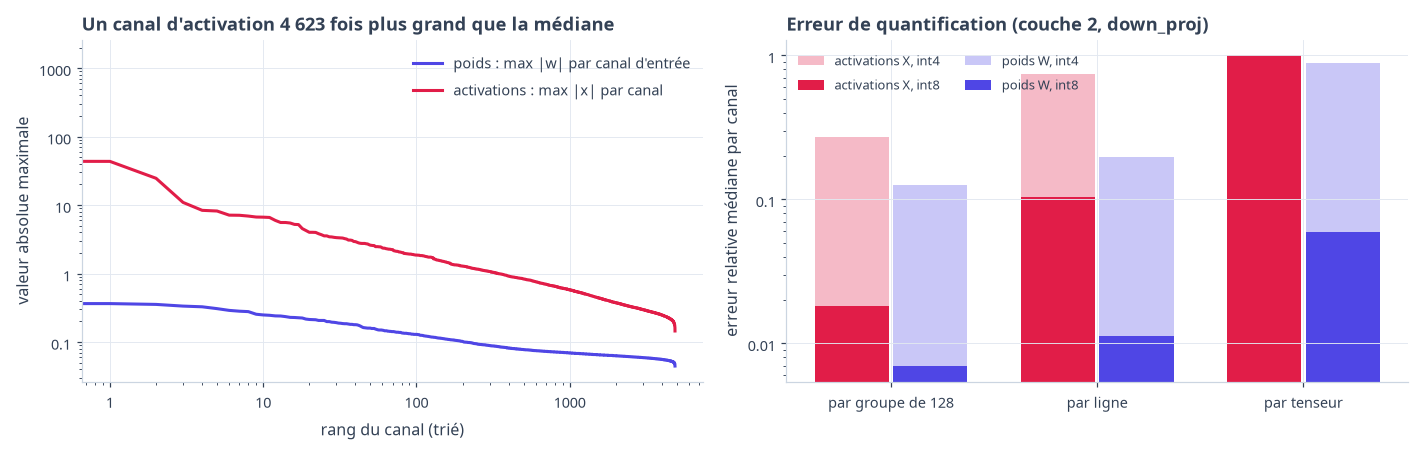

In [3]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)
layer = model.model.layers[2].mlp
acts = {}


def grab(module, inputs, output):
    acts["x"] = inputs[0][0].detach().float().cpu().numpy()  # un hook qui renvoie None ne modifie pas la sortie


h = layer.down_proj.register_forward_hook(grab)
with torch.no_grad():
    inf.retry_oom(model, tok(inf.CALIB_TEXT, return_tensors="pt")["input_ids"].cuda())
h.remove()
W = layer.down_proj.weight.detach().float().cpu().numpy()  # (896, 4864)
X = acts["x"]  # (tokens, 4864) : activations en entrée de down_proj, couche 2


def median_channel_err(a, q):
    """Erreur relative médiane par canal d'entrée (colonne) : ce que subit un canal typique."""
    return float(np.median(np.linalg.norm(a - q, axis=0) / np.maximum(np.linalg.norm(a, axis=0), 1e-12)))


rows = []
for label, arr in [("poids W", W), ("activations X", X)]:
    for gran, kw in [("par tenseur", dict(axis=None)), ("par ligne", dict(axis=1)),
                     ("par groupe de 128", dict(group_size=128))]:
        for bits in [8, 4]:
            q, _ = inf.quantize_symmetric(arr, bits, **kw)
            rows.append({"tenseur": label, "granularité": gran, "bits": bits, "erreur": median_channel_err(arr, q)})
err = pd.DataFrame(rows).pivot_table(index=["tenseur", "granularité"], columns="bits", values="erreur")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
mx_w, mx_x = np.abs(W).max(0), np.abs(X).max(0)
ax.plot(np.sort(mx_w)[::-1], color=INDIGO, label="poids : max |w| par canal d'entrée")
ax.plot(np.sort(mx_x)[::-1], color=ROSE, label="activations : max |x| par canal")
ax.set_yscale("log"); plain_log_axis(ax, "y"); ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("rang du canal (trié)"); ax.set_ylabel("valeur absolue maximale")
ax.set_title(f"Un canal d'activation {mx_x.max() / np.median(mx_x):,.0f} fois plus grand que la médiane".replace(",", " "))
ax.legend()
ax = axes[1]
e8 = err[8].unstack(0); e4 = err[4].unstack(0)
xx = np.arange(len(e8))
for j, (col, c) in enumerate(zip(e8.columns, [ROSE, INDIGO])):
    ax.bar(xx + (j - 0.5) * 0.38, e4[col], 0.36, color=c, alpha=0.3, label=f"{col}, int4")
    ax.bar(xx + (j - 0.5) * 0.38, e8[col], 0.36, color=c, label=f"{col}, int8")
ax.set_xticks(xx, e8.index); ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_ylabel("erreur relative médiane par canal"); ax.set_title("Erreur de quantification (couche 2, down_proj)")
ax.legend(fontsize=8.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
err.style.format("{:.4f}")

Les poids sont « sages » : leur maximum varie peu d'un canal à l'autre, et l'erreur int8
reste faible même avec une seule échelle. Les activations, elles, ont quelques **canaux
aberrants** (ici un canal dépasse la médiane de plusieurs ordres de grandeur, phénomène
connu sous le nom de *massive activations*) : avec une échelle par tenseur, ce canal fixe
le pas de la grille et la plupart des autres valeurs sont arrondies à zéro (erreur proche
de 100 % pour un canal typique). Une échelle **par token** (par ligne) aide en 8 bits mais
reste très insuffisante en 4 bits, car le canal aberrant est présent dans tous les tokens ;
il faut descendre au groupe.
C'est l'observation à l'origine de LLM.int8() (Dettmers et al., 2022), qui garde ces
canaux en 16 bits, et de SmoothQuant, qui transfère la difficulté des activations vers les
poids.

> **À retenir.** L'erreur d'arrondi est proportionnelle à l'échelle, donc au plus grand
> coefficient du groupe. Les poids se quantifient bien ; les activations, à cause de leurs
> canaux aberrants, demandent des schémas plus fins : c'est pourquoi la quantification des
> poids seuls domine en pratique.

## 3. Quantification mesurée : mémoire, vitesse, perplexité (section *Model compression*)

**Qualité selon le nombre de bits.** On simule la quantification des poids seuls (on
remplace chaque matrice par sa version quantifiée puis déquantifiée, en arrondi au plus
proche, sans aucune calibration) et on mesure la perplexité de Qwen2.5-0.5B sur un texte
d'évaluation (rédigé pour ce dépôt, environ 230 tokens).

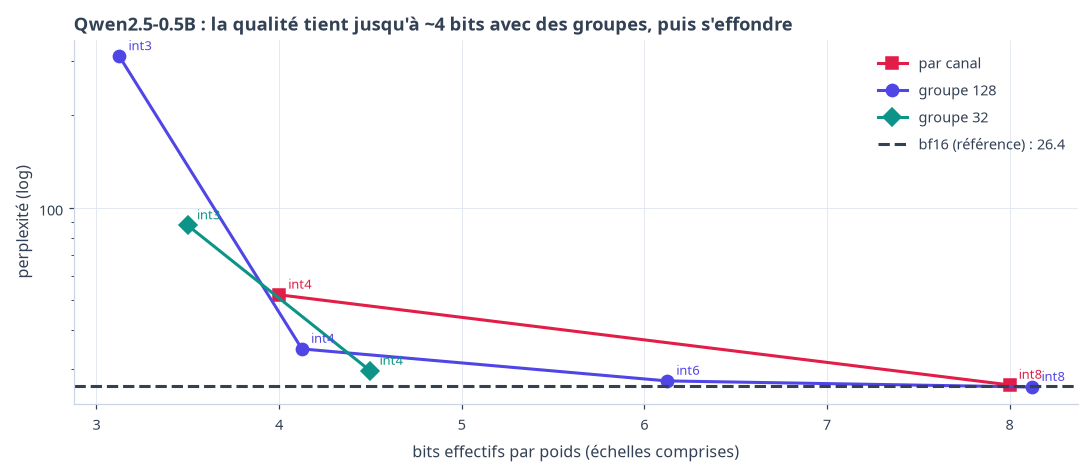

schéma,bits effectifs / poids,perplexité
int8 par canal,8.00,26.6
int8 groupe 128,8.12,26.2
int6 groupe 128,6.12,27.4
int4 par canal,4.00,52.2
int4 groupe 128,4.12,34.8
int4 groupe 32,4.50,29.5
int3 groupe 128,3.12,310.2
int3 groupe 32,3.50,87.6


In [4]:
state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # copie sur CPU
ppl_ref = inf.retry_oom(inf.perplexity_of, model, tok, inf.EVAL_TEXT)
configs = [(8, None), (8, 128), (6, 128), (4, None), (4, 128), (4, 32), (3, 128), (3, 32)]
rows = []


def ppl_fake_quant(bits, g):
    model.load_state_dict(state)
    inf.fake_quantize_model_(model, bits, g)
    return inf.perplexity_of(model, tok, inf.EVAL_TEXT)


for bits, g in configs:
    rows.append({"schéma": f"int{bits} " + (f"groupe {g}" if g else "par canal"), "bits": bits, "groupe": g,
                 "bits effectifs / poids": inf.quant_bits_per_weight(bits, g),
                 "perplexité": inf.retry_oom(ppl_fake_quant, bits, g)})
model.load_state_dict(state)
fq = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.4))
for gname, c, mk in [("par canal", ROSE, "s"), ("groupe 128", INDIGO, "o"), ("groupe 32", TEAL, "D")]:
    sub = fq[fq["schéma"].str.contains(gname)]
    ax.plot(sub["bits effectifs / poids"], sub["perplexité"], mk + "-", color=c, label=gname, ms=8)
    for _, r in sub.iterrows():
        ax.annotate(r["schéma"].split()[0], (r["bits effectifs / poids"], r["perplexité"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=c)
ax.axhline(ppl_ref, color=SLATE, ls="--", label=f"bf16 (référence) : {ppl_ref:.1f}")
ax.set_yscale("log"); plain_log_axis(ax, "y", fmt=lambda v: f"{v:.0f}")
ax.set_xlabel("bits effectifs par poids (échelles comprises)"); ax.set_ylabel("perplexité (log)")
ax.set_title("Qwen2.5-0.5B : la qualité tient jusqu'à ~4 bits avec des groupes, puis s'effondre")
ax.legend()
plt.tight_layout(); plt.show()
fq[["schéma", "bits effectifs / poids", "perplexité"]].style.format(
    {"bits effectifs / poids": "{:.2f}", "perplexité": "{:.1f}"}).hide(axis="index")

En 8 bits, la perplexité ne bouge pratiquement pas. En 4 bits, une échelle par canal
dégrade déjà nettement le modèle, alors que des groupes de 128 ou 32 poids limitent la
casse pour un surcoût de 0,1 à 0,5 bit par poids. En 3 bits, même les groupes ne suffisent
plus avec un simple arrondi : il faut des méthodes calibrées (GPTQ, AWQ) qui choisissent
l'arrondi pour minimiser l'erreur sur les sorties. Notez qu'un modèle de 0,5 milliard de
paramètres est **plus fragile** qu'un gros modèle : chaque poids y porte plus
d'information.

**Mesures réelles avec bitsandbytes.** On charge Qwen2.5-1.5B en bf16, en int8 (LLM.int8 :
poids **et** activations en int8, canaux aberrants en 16 bits) et en nf4 (4 bits, poids
seuls, calcul en bf16). Pour chaque variante : empreinte mémoire, débit de decode (32
tokens, médiane de 3), durée d'un prefill de 512 tokens, perplexité.

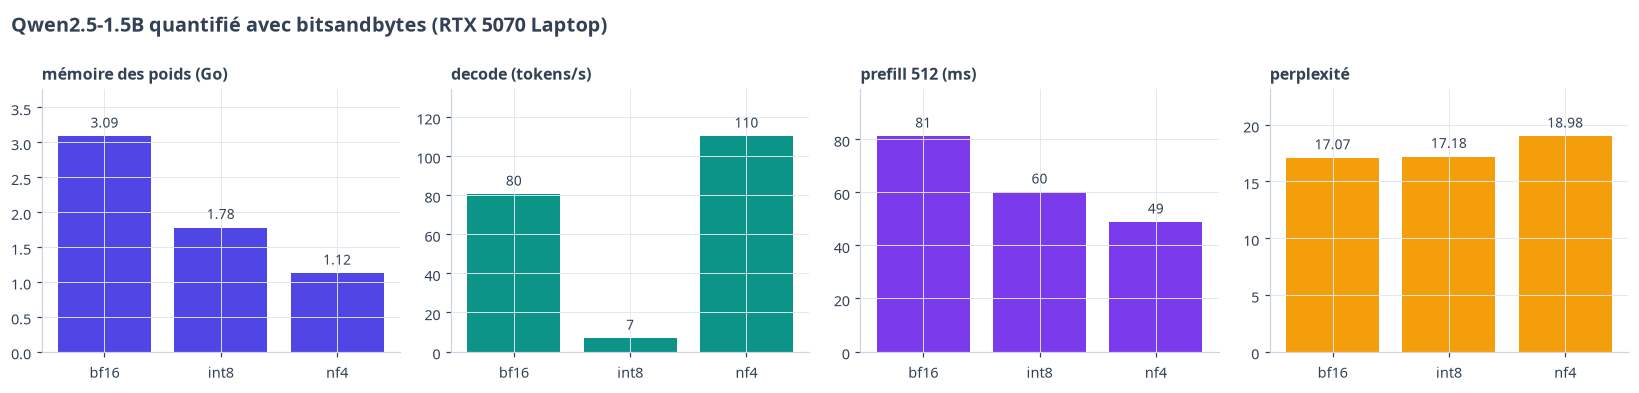

In [5]:
del layer, state
llm.free_gpu(); release(model)
del model


def measure_variant(qt):
    torch.cuda.reset_peak_memory_stats()
    tk, mdl = inf.load_model(llm.MEDIUM, qt)
    ids = tk("The history of computing began", return_tensors="pt")["input_ids"][0].tolist()
    dec = inf.time_fn(lambda: inf.greedy_generate(mdl, ids, 32), repeats=3, warmup=1)
    x = inf.random_ids(1, 512)
    with torch.no_grad():
        pre = inf.time_fn(lambda: mdl(x, logits_to_keep=1), repeats=5, warmup=1)
    out = {"variante": qt, "mémoire des poids (Go)": mdl.get_memory_footprint() / 1e9,
           "decode (tokens/s)": 32 / dec["median"], "prefill 512 (ms)": pre["median"] * 1e3,
           "perplexité": inf.perplexity_of(mdl, tk, inf.EVAL_TEXT)}
    release(mdl)
    return out


bnb = pd.DataFrame([inf.retry_oom(measure_variant, qt) for qt in ["bf16", "int8", "nf4"]]).set_index("variante")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col, c in zip(axes, bnb.columns, [INDIGO, TEAL, VIOLET, AMBER]):
    ax.bar(bnb.index, bnb[col], color=c)
    annotate_bars(ax, "{:.2f}" if bnb[col].max() < 30 else "{:.0f}")
    ax.set_title(col, fontsize=10.5); ax.set_ylim(0, bnb[col].max() * 1.22)
finish(fig, "Qwen2.5-1.5B quantifié avec bitsandbytes (RTX 5070 Laptop)")
plt.show()

Ce que montrent les mesures (les valeurs exactes varient d'une exécution à l'autre, les
rapports sont stables) :

- **mémoire** : int8 et nf4 divisent bien l'empreinte (environ 1,7x et 2,7x ; pas 2x et
  4x, car la table des plongements, partagée avec la tête de sortie, reste en bf16) ;
- **perplexité** : int8 est presque indiscernable du bf16, nf4 un peu au-dessus ;
- **vitesse** : c'est la surprise pédagogique. LLM.int8 est **plus lent** que le bf16 en
  decode comme en prefill : la décomposition des canaux aberrants et les conversions
  coûtent plus que l'économie de bande passante, sur un petit modèle. Le nf4 accélère en
  général le decode (moins d'octets à lire), mais ralentit le prefill, où la
  déquantification à la volée s'ajoute à un calcul déjà limité par les FLOPs.

Leçon : une quantification n'accélère que si un **noyau** efficace l'exploite (cf. cours 3).
Les moteurs de service (vLLM, TensorRT-LLM, llama.cpp) utilisent des noyaux int4 / fp8
dédiés (Marlin, AWQ, fp8 natif des tensor cores) qui, eux, tiennent la promesse : l'étude
de cas PyTorch du livre (figure 9-14) gagne nettement en débit en passant les poids de
Llama-7B en int8 puis int4.

> **À retenir.** Quantifier les poids réduit sûrement la mémoire, presque toujours sans
> perte en 8 bits, avec une perte modérée en 4 bits par groupes. Le gain de vitesse, lui,
> dépend du noyau : **mesurez** sur votre matériel avant de conclure.